# Assignment 2 preamble

Please remember to change the name of your copy of the assignment to include your name (and optionally UNI).

We're going to try having you submit the ipynb file (File -> Download .ipynb) rather than sharing through Google drive this time.

Most of the tasks/questions for this assignment are at the end but there is one in the middle so don't miss it!

# Setting up Colab

1.   Make sure you're signed into Colab through your Columbia account. This will be important for accessing data.
2.   Check you've requested a GPU (or TPU): go to Runtime -> Change runtime type -> Set "Hardware Accelerator". Colab will restart if needed.

Mount your Google drive. This should give you a link to follow where you'll copy a key that you'll paste in here. You can view files in the sidebar on the left under "Files".

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Load `torch`. Note the version on colab can lag behind the most current release. If you need something new you can install using e.g. !pip3 install torch==1.4.0

In [10]:
import torch
import torch.nn as nn
import torch.utils.data
assert(torch.cuda.is_available()) # if this fails go to Runtime -> Change runtime type -> Set "Hardware Accelerator"
print("Torch version:", torch.__version__)

Torch version: 2.11.0+cu130


## Utilities

We'll be using a "one hot" encoding of DNA sequence as the input to our CNN. This can actually be a bottleneck as it runs on the CPU so we use Cython to speed things up.  

In [28]:
%load_ext Cython

In [29]:
%%cython

import numpy as np
np.get_include() # do we need this on colab?
cimport cython
cimport numpy as np

cdef dict bases={ 'A':<int>0, 'C':<int>1, 'G':<int>2, 'T':<int>3 }

@cython.boundscheck(False)
def one_hot( str string ):
    cdef np.ndarray[np.float32_t, ndim=2] res = np.zeros( (4,len(string)), dtype=np.float32 )
    cdef int j
    for j in range(len(string)):
        if string[j] in bases: # bases can be 'N' signifying missing: this corresponds to all 0 in the encoding
            res[ bases[ string[j] ], j ]=float(1.0)
    return(res)


# Pytorch basics

`pytorch` (as opposed to e.g. Theano, Tensorflow 1) uses *eager execution*: this lets you write computations as python code that you can test and debug, and later
1.   Backprop through (i.e. get gradients with respect to inputs)
2.   Run on the GPU for (hopefully!) big speedups.

Here's an example:

In [33]:
x_np = one_hot("CCGCGNGGNGGCAG")
x_tensor = torch.tensor(x_np)
print(x_tensor)
torch.sum(x_tensor, 1)

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.],
        [1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
        [0., 0., 1., 0., 1., 0., 1., 1., 0., 1., 1., 0., 0., 1.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])


tensor([1., 4., 7., 0.])

`torch` has equivalents for most `numpy` operations, for example here we got the row sums to check how often each base appeared in our sequence.

As a more exciting example, `torch.nn.functional` has convolutions implemented for us.

In [34]:
import torch.nn.functional as F
help(F.conv1d)

Help on built-in function conv1d in module torch:

conv1d(...)
    conv1d(input, weight, bias=None, stride=1, padding=0, dilation=1, groups=1) -> Tensor

    Applies a 1D convolution over an input signal composed of several input
    planes.

    This operator supports :ref:`TensorFloat32<tf32_on_ampere>`.

    See :class:`~torch.nn.Conv1d` for details and output shape.

    Note:
        In some circumstances when given tensors on a CUDA device and using CuDNN, this operator may select a nondeterministic algorithm to increase performance. If this is undesirable, you can try to make the operation deterministic (potentially at a performance cost) by setting ``torch.backends.cudnn.deterministic = True``. See :doc:`/notes/randomness` for more information.

    Note:
        This operator supports complex data types i.e. ``complex32, complex64, complex128``.


    Args:
        input: input tensor of shape :math:`(\text{minibatch} , \text{in\_channels} , iW)`
        weight: filters of sha

Notice `conv1d` expects
1. `input` to have shape batchsize x #input_channels x length (as a warning, `tensorflow` expects batchsize x length x #input_channels!)
2. `weight` (i.e. the filters) to have shape #output_channels x #input_channels x filter_width.

We can make a random tensor for the filters (weights), and then execute the convolution

In [35]:
x_batch = x_tensor[None,:,:] # make a "batch" of size 1
filter_width = 5
my_weights = torch.randn(1, 4, filter_width) # 1 output channels, 4 input channels, filter width = 5
convolution_output = F.conv1d(x_batch, my_weights)
convolution_output

tensor([[[3.2166, 2.0380, 1.5237, 4.2534, 0.5135, 1.2025, 3.0865, 1.7476,
          0.4145, 2.6845]]])

Let's check `torch` got the right answer. Here's the calculation for the first position (for data point 0 and output channel 0):

In [36]:
(x_batch[0,:,0:filter_width] * my_weights[0,:,:]).sum()

tensor(3.2166)

## Task

**Write a for loop to manually calculate the remaining terms in the convolution [1 point]**

In [37]:
my_convolution_output = torch.zeros([1, 1, x_batch.shape[2] - (filter_width-1)])
for i in range(my_convolution_output.shape[2]):
    window_of_batch = x_batch[0, :, i:i+filter_width] #get the correct matrix
    my_convolution_output[0,0,i] = (window_of_batch * my_weights[0]).sum() #multiply element-wise by each weight
assert( ((convolution_output - my_convolution_output).abs() < 1e-6).all() )

Note the effect of the (0 padded) convolution on the shape of the output: the sequence length has gone from 14 to 10.

In [38]:
print( x_batch.shape, convolution_output.shape )

torch.Size([1, 4, 14]) torch.Size([1, 1, 10])


Without padding we lose (filter_width-1) positions.

`torch` has nice built in utilities for setting up neural network (NN) layers. For example, we can make a 1D convolutional layer like this:

In [39]:
torch.manual_seed(2) # I played with different initialization here!
my_first_conv_layer = nn.Conv1d(4, 1, 14, padding = 0) # 4 input channels, 1 output channels, filter width 14, no padding
my_first_conv_layer

Conv1d(4, 1, kernel_size=(14,), stride=(1,))

We can use this layer like a function (applied to tensors):

In [40]:
my_first_conv_layer(x_batch)

tensor([[[-0.3852]]], grad_fn=<ConvolutionBackward0>)

But if `my_first_conv_layer` behaves like a function, where are the weights? They're there (along with biases), but they're a little hidden:

In [41]:
list(my_first_conv_layer.parameters())

[Parameter containing:
 tensor([[[ 0.0307, -0.0318,  0.0366, -0.0068,  0.0571,  0.0318, -0.0154,
           -0.1080,  0.0305, -0.1183,  0.0176,  0.0089, -0.0294,  0.1093],
          [ 0.0089,  0.0554,  0.0566, -0.0788, -0.0514,  0.1285, -0.1309,
           -0.0091, -0.0106,  0.0948, -0.0127,  0.0352, -0.0064, -0.0748],
          [-0.0757, -0.0649, -0.1214, -0.0867,  0.0314,  0.0879,  0.0066,
           -0.0613,  0.0587, -0.0513, -0.0296, -0.0733, -0.0420, -0.1238],
          [ 0.0570,  0.0520,  0.0265,  0.0656,  0.0566,  0.0059,  0.0142,
            0.0102,  0.0713,  0.0898,  0.0960,  0.0775, -0.0326, -0.0059]]],
        requires_grad=True),
 Parameter containing:
 tensor([-0.0272], requires_grad=True)]

But where did these numbers come from? `torch` by default initializes using the very reasonable [Kaiming/He initalization](https://arxiv.org/abs/1502.01852) which aims to keep the variance of the hidden layer activations reasonably stable (constant in expectation) through the network.

# My First Convolutional Neural Network

We're ready to make the simplest CNN possible where we just take the max over all the convolution outputs:

In [42]:
def my_simplest_CNN(x):
    net = my_first_conv_layer(x)
    net = net[:,0,:] # only one output channel!
    # take maximum over channel ("global max pooling")
    net = torch.max(net, dim=1).values # max returns namedtuple (values, indices)
    net = torch.sigmoid(net) # aka logistic to get output in [0,1]
    return(net)

my_simplest_CNN(x_batch)

tensor([0.4049], grad_fn=<SigmoidBackward0>)

## Loading data

To test this out we need some data! Our first task will be predict binding of the important transcriptional repressor CTCF in a human lung cancer cell line called A549. The data is available from ENCODE including merging replicate experiments using the "irreproducible discovery rate" (IDR) [paper](https://arxiv.org/abs/1110.4705) [code](https://github.com/spundhir/idr). Genomics data representing discrete binding events is typically stored in the  `bed` format, which is described on the UCSC Genome Browser [website](https://genome.ucsc.edu/FAQ/FAQformat.html#format1). This bed file has some additional columns we will ignore.

In [15]:
import pandas as pd
DATADIR = "/content/drive/MyDrive/Colab Notebooks/" # might need to change this
binding_data = pd.read_csv(DATADIR + "ENCFF300IYQ.bed", sep='\t', usecols=range(6), names=("chrom","start","end","name","score","strand"))
binding_data = binding_data[ ~binding_data['chrom'].isin(["chrX","chrY"]) ] # only keep autosomes (non sex chromosomes)
binding_data = binding_data.sort_values(['chrom', 'start']).drop_duplicates() # sort so we can interleave negatives
binding_data[:10]

,chrom,start,end,name,score,strand
3417,chr1,714156,714372,.,1000,.
28093,chr1,805243,805372,.,1000,.
32029,chr1,840059,840248,.,1000,.
17195,chr1,848298,848514,.,1000,.
6610,chr1,855056,855272,.,1000,.
10598,chr1,856479,856695,.,1000,.
15904,chr1,858493,858709,.,1000,.
16616,chr1,860345,860561,.,1000,.
10818,chr1,860967,861183,.,1000,.
31703,chr1,873565,873753,.,1000,.


`chrom` is the chromosome (we filter out the sex chromosomes X and Y to avoid bias from these being haploid, you could try keeping them though). `start` and `end` are positions in the genome. `name` and `strand` aren't used here. Some genomics assays (e.g. RNA-seq) correspond to one strand of the DNA or the other. However, for our purposes at least we can consider ChIP-seq and ATAC-seq as "unstranded", which is why that column is all "." rather than + or -.  `score` is a quantitative measure of binding. We'll ignore this for now (since all these peaks are statistically significant), but you could try to incorporate it in your model training if you want (e.g. multitask for binary binding plus predicting `score`).

We'll split the binding data into training, validation (chroms 2 and 3, ~) and test (chrom 1), which represents about 14% of the training data we have:

In [16]:
test_chromosomes = ["chr1"]
test_data = binding_data[ binding_data['chrom'].isin( test_chromosomes ) ]

validation_chromosomes = ["chr2","chr3"]
validation_data = binding_data[ binding_data['chrom'].isin(validation_chromosomes) ]

train_chromosomes = ["chr%i" % i for i in range(4, 22+1)]
train_data = binding_data[ binding_data['chrom'].isin( train_chromosomes ) ]

test_data.shape[0] / binding_data.shape[0], validation_data.shape[0] / binding_data.shape[0]

(0.0924340093163318, 0.1410859643344469)

We'll also need the human genome, which we provide here as a pickle since it's faster to load compared to reading in a text file.

It's worth knowing that the human genome has different *versions* that are released as more missing parts are resolved by continued sequencing and assembly efforts. Version `GRCh37` (also called `hg19`) was released in 2009, and `GRCh38` (`hg38`) was released in 2013. We'll be using `hg19` here but `GRCh38` is finally becoming more standard so always check your data is what you think it is.

This will take a minute or two.

In [19]:
import pickle
#genome = pickle.load(open(DATADIR+"hg38.pkl","rb")) # this is here in case there's hg38 data you want to analyse
genome = pickle.load(open(DATADIR+"hg19-001.pickle","rb")) # I had to change the file name here because my human genome file I downloaded downloaded as -001

`genome` is just a dictionary where the keys are the chromosome names and the values are strings representing the actual DNA:

In [46]:
genome["chr13"][100000000:100000010]

'GTGATAACGT'

You'll find a substantial proportion of each chromosome is "N"s:

In [47]:
genome["chr13"].count("N") / len(genome["chr13"])

0.17000973119030308

Ns represents "missing" regions, typically because the region has too many repetitive sequences making mapping impossible, which is especially the case in [centrosomes](https://en.wikipedia.org/wiki/Centrosome) and [telomeres](https://en.wikipedia.org/wiki/Telomere). Resolving these difficult to map regions is an ongoing effort.

We'll use the `torch` data loading utilities (nicely documented [here](https://pytorch.org/docs/stable/data.html)) to handle
1. Grouping individual (x,y) pairs into minibatches.
2. Converting `numpy` arrays into `torch` tensors.

We could also use `num_workers>0` to have a background process generating the next batch using the CPU while the GPU is working, but in my experience this actually slows things down. If you were in a computer vision setting where you wanted to do intensive [data augmentation](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) it might make a difference.

In [20]:
# positive example: binding of protein onto sequence (ChIP-seq (TF ChIP-seq))
# negative example: the ones that do not overlap with the positive examples
# for chip-seq data: also shuffling nucleotides can be done to keep the GC content the same as positive example
# because sequencing has biases with GC content and this would be a way to "fix it"
class BedPeaksDataset(torch.utils.data.IterableDataset):

    def __init__(self, atac_data, genome, context_length):
        super(BedPeaksDataset, self).__init__()
        self.context_length = context_length
        self.atac_data = atac_data
        self.genome = genome

    def __iter__(self):
        prev_end = 0
        prev_chrom = ""
        for i,row in enumerate(self.atac_data.itertuples()):
            midpoint = int(.5 * (row.start + row.end))
            seq = self.genome[row.chrom][ midpoint - self.context_length//2:midpoint + self.context_length//2]
            yield(one_hot(seq), np.float32(1)) # positive example

            if prev_chrom == row.chrom and prev_end < row.start:
                midpoint = int(.5 * (prev_end + row.start))
                seq = self.genome[row.chrom][ midpoint - self.context_length//2:midpoint + self.context_length//2]
                yield(one_hot(seq), np.float32(0)) # negative example midway inbetween peaks, could randomize

            prev_chrom = row.chrom
            prev_end = row.end

train_dataset = BedPeaksDataset(train_data, genome, 100)
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=1000, num_workers = 0)

train_data

,chrom,start,end,name,score,strand
6094,chr10,119905,120121,.,977,.
18051,chr10,122432,122648,.,1000,.
14300,chr10,183139,183355,.,1000,.
19341,chr10,276844,276914,.,1000,.
17727,chr10,325694,325910,.,1000,.
...,...,...,...,...,...,...
8866,chr9,140862899,140863115,.,998,.
31972,chr9,140916866,140917028,.,1000,.
22970,chr9,140948983,140949199,.,1000,.
4812,chr9,140960493,140960709,.,1000,.


## Training

Let's train our super simple CNN using stochastic gradient descent:

In [49]:
import timeit
start_time = timeit.default_timer()

torch.set_grad_enabled(True) # we'll need gradients

for epoch in range(10): # run for this many epochs
    losses = []
    accuracies = []
    for (x,y) in train_dataloader: # iterate over minibatches

        output = my_simplest_CNN(x) # forward pass
        # in practice (and below) we'll use more numerically stable built-in
        # functions for the loss
        loss = - torch.mean( y * torch.log(output) + (1.-y) * torch.log(1.-output) )
        loss.backward() # back propagation

        # iterate over parameter tensors: just the layer1 weights and bias here
        for parameters in my_first_conv_layer.parameters():
            parameters.data -= 1.0 * parameters.grad # in practive reduce or adapt learning rate
            parameters.grad.data.zero_() # torch accumulates gradients so need to reset

        losses.append(loss.detach().numpy()) # convert back to numpy
        accuracy = torch.mean( ( (output > .5) == (y > .5) ).float() )
        accuracies.append(accuracy.detach().numpy())

    elapsed = float(timeit.default_timer() - start_time)
    print("Epoch %i %.2fs/epoch Loss: %.4f Acc: %.4f" % (epoch+1, elapsed/(epoch+1), np.mean(losses), np.mean(accuracies)))


Epoch 1 3.26s/epoch Loss: 0.5535 Acc: 0.7388
Epoch 2 2.68s/epoch Loss: 0.4895 Acc: 0.7632
Epoch 3 2.76s/epoch Loss: 0.4492 Acc: 0.7939
Epoch 4 2.60s/epoch Loss: 0.3835 Acc: 0.8322
Epoch 5 2.54s/epoch Loss: 0.3422 Acc: 0.8540
Epoch 6 2.77s/epoch Loss: 0.3321 Acc: 0.8574
Epoch 7 2.73s/epoch Loss: 0.3286 Acc: 0.8587
Epoch 8 2.65s/epoch Loss: 0.3269 Acc: 0.8589
Epoch 9 2.59s/epoch Loss: 0.3260 Acc: 0.8591
Epoch 10 2.54s/epoch Loss: 0.3255 Acc: 0.8592


So we can get pretty decent accuracy even with this very simple CNN (although I cheated a bit by trying a few random seeds and knowing that the CTCF consensus motif is 14nt long so would require a width 14 filter).

In [50]:
validation_dataset = BedPeaksDataset(validation_data, genome, 100)
validation_dataloader = torch.utils.data.DataLoader(validation_dataset, batch_size=1000)
accuracies = [ torch.mean( ( (my_simplest_CNN(x)  > .5) == (y > .5) ).float() ).detach().cpu().numpy() for (x,y) in validation_dataloader ]
np.mean(accuracies)

np.float32(0.83062035)

The validation accuracy is very similiar to the train accuracy, suggesting we're not overfitting (as we would expect with such a simple model).

## Model interpretation

Since this model used only a single convolutional filter it's very easy to interpret how it's making predictions. In genetics it's common to plot position weight matrices as "sequence logos":

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 18.3 MB/s  0:00:00


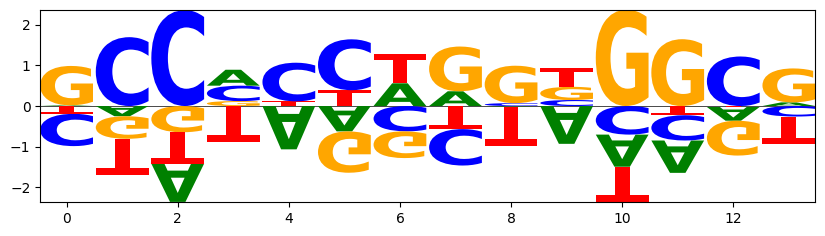

In [51]:
!pip install logomaker
import logomaker
pwm = my_first_conv_layer.weight.detach().cpu().numpy().squeeze()
pwm -= pwm.mean(0, keepdims=True) # remove spurious degrees of freedom
pwm_df = pd.DataFrame(data = pwm.transpose(), columns=("A","C","G","T"))
crp_logo = logomaker.Logo(pwm_df) # CCACCAGG(G/T)GGCG

Characters above (below) the x-axis correspond to positive (negative) values. Our model has some additional degrees of freedom (we could add a constant k to each column of the filter and substract k from the bias without changing the prediction) which we remove. Compare this to the "known" sequence motif: [JASPAR CTCF](http://jaspar.genereg.net/matrix/MA0139.1/) to see it's a pretty good match.

# A full LeNet-type CNN

Let's see if we can do better with a full CNN. While it's not strictly necessary it's convenient to encapsulate the model as a class inheriting from `nn.Module`. This allows automatic handling of things like:
1. Extracting all model parameters.
2. Setting all layers to train or eval mode (for layers like dropout that behave differently in the two settings).
Note that here we used the model architecture to specify the length of sequence (the "sequence context") that is considered (stored as cnn_1d.seq_len). "num_chunks" here corresponds to the sequence length of the hidden layer after the last convolutional layer. The other common approach is to instead specify the sequence context and use the formula we covered in class to calculate the sequence length L for each each hidden layer (you're welcome to try implementing that approach!)

In [21]:
class CNN_1d(nn.Module):

    def __init__(self,
                 n_output_channels = 1,
                 filter_widths = [15, 5],
                 num_chunks = 5,
                 max_pool_factor = 4,
                 nchannels = [4, 32, 32],
                 n_hidden = 32,
                 dropout = 0.2):

        super(CNN_1d, self).__init__()
        self.rf = 0 # running estimate of the receptive field
        self.chunk_size = 1 # running estimate of num basepairs corresponding to one position after convolutions

        conv_layers = []
        for i in range(len(nchannels)-1):
            conv_layers += [ nn.Conv1d(nchannels[i], nchannels[i+1], filter_widths[i], padding = 0),
                        nn.BatchNorm1d(nchannels[i+1]), # tends to help give faster convergence: https://arxiv.org/abs/1502.03167
                        nn.Dropout2d(dropout), # popular form of regularization: https://jmlr.org/papers/v15/srivastava14a.html
                        nn.MaxPool1d(max_pool_factor),
                        nn.ELU(inplace=True)  ] # popular alternative to ReLU: https://arxiv.org/abs/1511.07289
            assert(filter_widths[i] % 2 == 1) # assume this
            self.rf += (filter_widths[i] - 1) * self.chunk_size
            self.chunk_size *= max_pool_factor

        # If you have a model with lots of layers, you can create a list first and
        # then use the * operator to expand the list into positional arguments, like this:
        self.conv_net = nn.Sequential(*conv_layers)

        self.seq_len = num_chunks * self.chunk_size + self.rf # amount of sequence context required

        print("Receptive field:", self.rf, "Chunk size:", self.chunk_size, "Number chunks:", num_chunks)

        self.dense_net = nn.Sequential( nn.Linear(nchannels[-1] * num_chunks, n_hidden),
                                        nn.Dropout(dropout),
                                        nn.ELU(inplace=True),
                                        nn.Linear(n_hidden, n_output_channels) )

    def forward(self, x):
        net = self.conv_net(x)
        net = net.view(net.size(0), -1)
        net = self.dense_net(net)
        return(net)

cnn_1d = CNN_1d()

print("Input length:", cnn_1d.seq_len)

cnn_1d

Receptive field: 30 Chunk size: 16 Number chunks: 5
Input length: 110


CNN_1d(
  (conv_net): Sequential(
    (0): Conv1d(4, 32, kernel_size=(15,), stride=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): Dropout2d(p=0.2, inplace=False)
    (3): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (4): ELU(alpha=1.0, inplace=True)
    (5): Conv1d(32, 32, kernel_size=(5,), stride=(1,))
    (6): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): Dropout2d(p=0.2, inplace=False)
    (8): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (9): ELU(alpha=1.0, inplace=True)
  )
  (dense_net): Sequential(
    (0): Linear(in_features=160, out_features=32, bias=True)
    (1): Dropout(p=0.2, inplace=False)
    (2): ELU(alpha=1.0, inplace=True)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

The `torch` output nicely illustrates the various layers in our network. We have two convolutional units each doing conv -> batchnorm -> dropout -> maxpooling -> activation, followed by two layers of dense network, including a dropout layer.

We'll recreate the dataloaders to satisfy the input sequence length requirement of the new model.


In [22]:
train_dataset = BedPeaksDataset(train_data, genome, cnn_1d.seq_len)
train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=1000, num_workers = 0)
validation_dataset = BedPeaksDataset(validation_data, genome, cnn_1d.seq_len)
validation_dataloader = torch.utils.data.DataLoader(validation_dataset, batch_size=1000)


## Transfering to the GPU
The previous example actually ran on the CPU. Now we're using a more complex model it'll be worth running on the GPU. To do that we need to transfer both model and data. Transfering the model:

In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_1d.to(device)
print(device)

cuda


Check that this says `cuda` not `cpu`! You need to go to Runtime -> Change runtime type -> Set "Hardware Accelerator" -> GPU (or TPU) if not.

Next we'll set up the optimizer. `torch` has a number of [optimizers](https://pytorch.org/docs/stable/optim.html), most of which are variants of SGD. [Adam](https://arxiv.org/abs/1412.6980) with the [AMSgrad convergence fix](https://openreview.net/forum?id=ryQu7f-RZ) is a good default in my experience.

In [32]:
optimizer = torch.optim.Adam(cnn_1d.parameters(), amsgrad=True)

We define a training loop which can be used for both training and validation loops by setting the `train_flag`.

In [25]:
def run_one_epoch(train_flag, dataloader, cnn_1d, optimizer, device="cuda"):

    torch.set_grad_enabled(train_flag)
    cnn_1d.train() if train_flag else cnn_1d.eval()

    losses = []
    accuracies = []

    for (x,y) in dataloader: # collection of tuples with iterator

        (x, y) = ( x.to(device), y.to(device) ) # transfer data to GPU

        output = cnn_1d(x) # forward pass
        output = output.squeeze() # remove spurious channel dimension
        loss = F.binary_cross_entropy_with_logits( output, y ) # numerically stable

        if train_flag:
            loss.backward() # back propagation
            optimizer.step()
            optimizer.zero_grad()

        losses.append(loss.detach().cpu().numpy())
        accuracy = torch.mean( ( (output > 0.0) == (y > 0.5) ).float() ) # output is in logit space so threshold is 0.
        accuracies.append(accuracy.detach().cpu().numpy())

    return( np.mean(losses), np.mean(accuracies) )

## Training
Ok let's train! We'll keep track of validation loss to do [early stopping](https://en.wikipedia.org/wiki/Early_stopping): if we don't see any improvement in the validation validation loss for 10 consecutive epochs then we stop training. This will take a few minutes.

In [36]:
train_accs = []
val_accs = []
patience = 10 # for early stopping
patience_counter = patience
best_val_loss = np.inf
check_point_filename = 'cnn_1d_checkpoint.pt' # to save the best model fit to date
for epoch in range(100):
    start_time = timeit.default_timer()
    train_loss, train_acc = run_one_epoch(True, train_dataloader, cnn_1d, optimizer, device)
    val_loss, val_acc = run_one_epoch(False, validation_dataloader, cnn_1d, optimizer, device)
    train_accs.append(train_acc)
    val_accs.append(val_acc)
    if val_loss < best_val_loss:
        torch.save(cnn_1d.state_dict(), check_point_filename)
        best_val_loss = val_loss
        patience_counter = patience
    else:
        patience_counter -= 1
        if patience_counter <= 0:
            cnn_1d.load_state_dict(torch.load(check_point_filename)) # recover the best model so far
            break
    elapsed = float(timeit.default_timer() - start_time)
    print("Epoch %i took %.2fs. Train loss: %.4f acc: %.4f. Val loss: %.4f acc: %.4f. Patience left: %i" %
          (epoch+1, elapsed, train_loss, train_acc, val_loss, val_acc, patience_counter ))

Epoch 1 took 2.16s. Train loss: 0.5349 acc: 0.7223. Val loss: 0.4235 acc: 0.7921. Patience left: 10
Epoch 2 took 2.16s. Train loss: 0.4388 acc: 0.7815. Val loss: 0.3468 acc: 0.8375. Patience left: 10
Epoch 3 took 2.19s. Train loss: 0.3766 acc: 0.8213. Val loss: 0.2975 acc: 0.8676. Patience left: 10
Epoch 4 took 2.43s. Train loss: 0.3321 acc: 0.8478. Val loss: 0.2547 acc: 0.8904. Patience left: 10
Epoch 5 took 3.92s. Train loss: 0.3014 acc: 0.8642. Val loss: 0.2352 acc: 0.9024. Patience left: 10
Epoch 6 took 2.13s. Train loss: 0.2825 acc: 0.8763. Val loss: 0.2220 acc: 0.9104. Patience left: 10
Epoch 7 took 2.17s. Train loss: 0.2690 acc: 0.8830. Val loss: 0.2168 acc: 0.9132. Patience left: 10
Epoch 8 took 2.18s. Train loss: 0.2596 acc: 0.8887. Val loss: 0.2039 acc: 0.9194. Patience left: 10
Epoch 9 took 2.14s. Train loss: 0.2494 acc: 0.8935. Val loss: 0.1999 acc: 0.9207. Patience left: 10
Epoch 10 took 2.79s. Train loss: 0.2425 acc: 0.8984. Val loss: 0.1979 acc: 0.9228. Patience left: 10

Rather than trying to stare at those numbers let's plot training and validation accuracy:

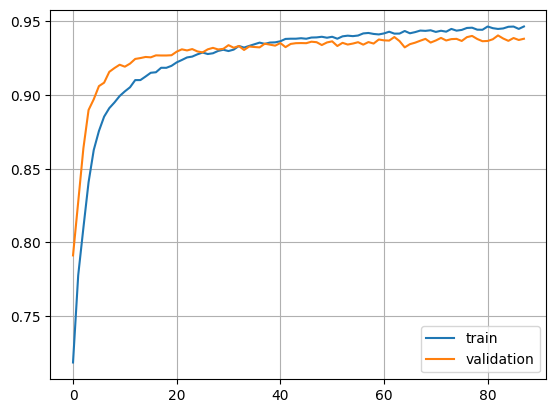

In [58]:
import matplotlib.pyplot as plt
plt.plot(train_accs, label="train")
plt.plot(val_accs, label="validation")
plt.legend()
plt.grid(which="both")

Unusually the validation accuracy is higher than the train accuracy in some places! This could be due to (at least) two factors:
1. Relatively small validation set so the estimate is noisy.
2. Dropout introduces noise into the predictions during training but not validation (as it should).
We could actually test this by evaluating on the training data without dropout:

In [59]:
train_loss, train_acc = run_one_epoch(False, train_dataloader, cnn_1d, optimizer, device)
val_loss, val_acc = run_one_epoch(False, validation_dataloader, cnn_1d, optimizer, device)
print(train_acc, val_acc)

0.9594086 0.9400387


As expected, the validation accuracy is a little lower. Strictly speaking we should also check performance on the test set since we used the validation set to do early stopping.

In [60]:
test_dataset = BedPeaksDataset(test_data, genome, cnn_1d.seq_len)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=1000)
test_loss, test_acc = run_one_epoch(False, test_dataloader, cnn_1d, optimizer, device)
test_acc

np.float32(0.9470395)

Nice, the test set accuracy is high too.

## Model interpretation

Model interpretation is an active area of research for CNNs. Two baseline approaches in genomics are *in silico* mutagenesis and saliency maps. Good approaches exist for explaining the prediction for a single instance: explaining how the model works globally is still a challenge in general.

### in silico mutatgenesis

This approach is specific to genomics where we can imagine making individual "point" mutations (changing just one base) and seeing what effect that has on the model's prediction. In computer vision there isn't a direct analogy: deleting or changing a single pixel would rarely (if ever) change the prediction we would expect (although CNNs are not necessarily robust to such changes - adversarial training attempts to make them so).  

*in silico* mutagenesis can be used both for model interpretation (as we do here) and predicting the effects of real mutations/genetic differences between individuals.

We'll just run mutagenesis for the first batch of the validation data:

In [61]:
torch.set_grad_enabled(False)
for (x_cpu,y_cpu) in validation_dataloader:
    x = x_cpu.to(device)
    y = y_cpu.to(device)
    output = cnn_1d(x).squeeze()
    output = torch.sigmoid(output)
    delta_output = torch.zeros_like(x, device=device)
    # loop over all positions changing to each position nucleotide
    # note everything is implicitly parallelized over the batch here
    for seq_idx in range(cnn_1d.seq_len): # iterate over sequence
        for nt_idx in range(4): # iterate over nucleotides
            x_prime = x.clone() # make a copy of x
            x_prime[:,:,seq_idx] = 0. # change the nucleotide to nt_idx
            x_prime[:,nt_idx,seq_idx] = 1.
            output_prime = cnn_1d(x_prime).squeeze()
            output_prime = torch.sigmoid(output_prime)
            delta_output[:,nt_idx,seq_idx] = output_prime - output
    break # just do this for first batch

Note how computationally expensive this is: for every instance we do inference $4 \times L$ times (we could make this $3 \times L$ easily enough).

We'll visualize just four (2 positive 2 negative) examples:

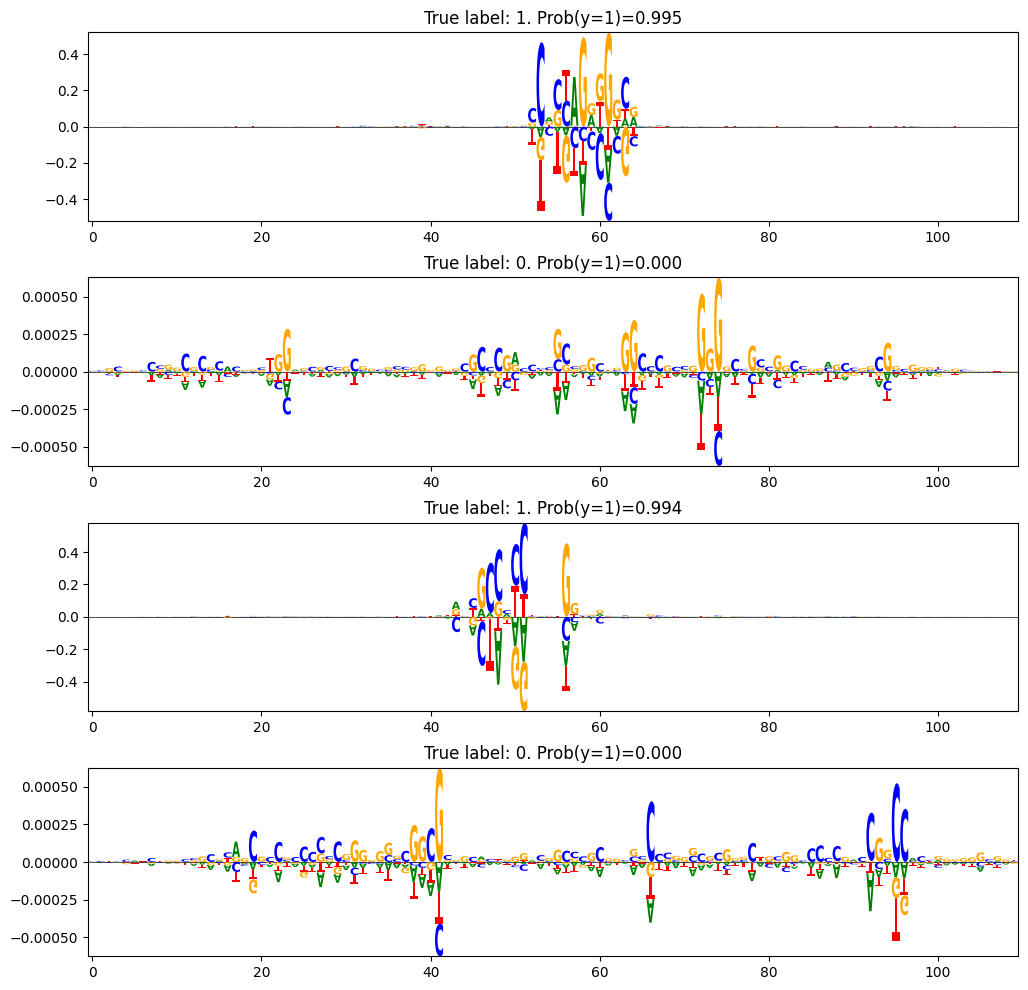

In [62]:
delta_output_np = delta_output.detach().cpu().numpy()
delta_output_np -= delta_output_np.mean(1, keepdims=True)
output_np = output.detach().cpu().numpy()
plt.figure(figsize = (12,12))
for i in range(1,5):
    ax = plt.subplot(4,1,i)
    pwm_df = pd.DataFrame(data = delta_output_np[i,:,:].transpose(), columns=("A","C","G","T"))
    crp_logo = logomaker.Logo(pwm_df, ax = ax) # CCGCGNGGNGGCAG or CTGCCNCCNCGCGG
    plt.title("True label: %i. Prob(y=1)=%.3f" % (y_cpu[i],output_np[i]))

plt.subplots_adjust(hspace = 0.3)

Note the difference in the y-axis scales! For the two positive examples there are clear regions in the sequence that if disrupted significantly impact the prediction. For the negative examples there is a scattering of "mutations" that would effect the prediction, presumably by randomly introducing a sequence that looks a little like the CTCF motif (we don't expect any specific features in these negative sequences).

### Saliency maps

This is the simplest approach to leverage the same backprop machinery that we use during training. The trick is that instead of taking the gradient w.r.t. parameters we'll now take the gradient w.r.t. inputs `x`. Specifically here we'll get the gradient of $P(y=1|x)$ w.r.t x. The `saliency` itself is defined as that gradient elementwise multiplied with `x` itself.

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


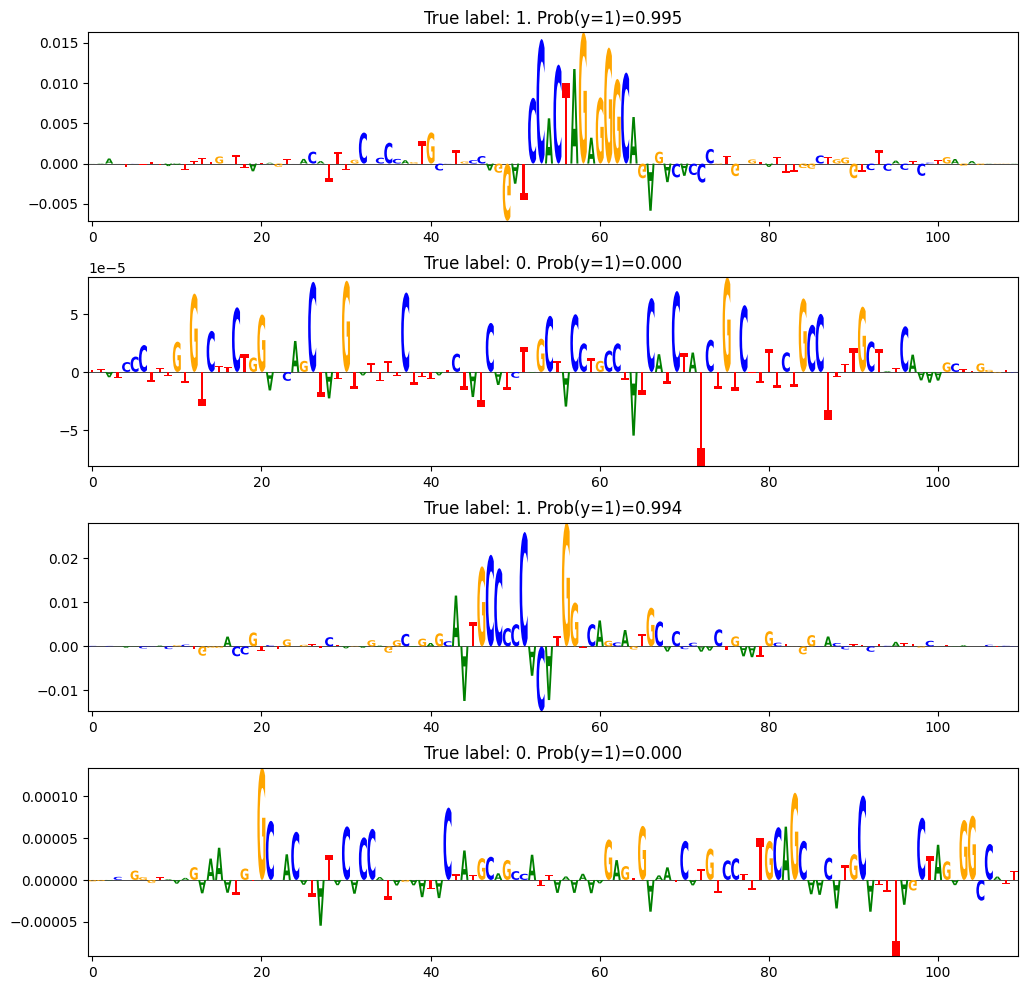

In [63]:
torch.set_grad_enabled(True)
x.requires_grad_() # tell torch we will want gradients wrt x (which we don't normally need)
output = cnn_1d(x).squeeze()
output = torch.sigmoid(output)
dummy = torch.ones_like(output) # in a multiclass model this would be a one-hot encoding of y
output.backward(dummy) # to get derivative wrt to x
gradient_np = x.grad.detach().cpu().numpy()
output_np = output.detach().cpu().numpy()
saliency = gradient_np * x_cpu.numpy()
plt.figure(figsize = (12,12))
for i in range(1,5):
    ax = plt.subplot(4,1,i) #,sharey=ax)
    pwm_df = pd.DataFrame(data = saliency[i,:,:].transpose(), columns=("A","C","G","T"))
    logomaker.Logo(pwm_df, ax=ax) # CCGCGNGGNGGCAG or CTGCCNCCNCGCGG
    plt.title("True label: %i. Prob(y=1)=%.3f" % (y_cpu[i],output_np[i]))

plt.subplots_adjust(hspace = 0.3)

This is much more computationally efficient than in silico mutagenesis, requiring only ONE forward and backward pass. Compare the two interpretation methods: for the positive examples the same sequence regions are highlighted (although the saliency map is noisier outside that region).

### Other interpretation approaches

There's a nice compedium and associated `torch` code for a number methods [here](https://github.com/utkuozbulak/pytorch-cnn-visualizations). Some that I would add:
1. DeepLIFT  [paper](https://arxiv.org/abs/1704.02685) [code](https://github.com/kundajelab/deeplift) - no `pytorch` support sadly.
2. DeepSHAP [paper](https://papers.nips.cc/paper/7062-a-unified-approach-to-interpreting-model-predictions) [code](https://github.com/slundberg/shap)
3. Influence functions. [paper](https://arxiv.org/abs/1703.04730) [code](https://github.com/kohpangwei/influence-release). A little different: finds which training points most strongly influence the current prediction.

## A more challenging task

CTCF binding is relatively easy to predict, mostly depending on homotypic binding with a strong motif. Here you'll attempt a more difficult task: predicting chromatin accessibility (as measured by ATAC-seq) for a mystery cell type (mysterious so you can fairly compete in the competition below!) Let's load data and split into training and validation - I've already removed chromosome 1 and 2 data as test set to be used in the competition at the end.

In [23]:
atac_data = pd.read_csv(DATADIR + "ATAC_data.bed", sep='\t', names=("chrom","start","end"))
atac_data = atac_data.sort_values(['chrom', 'start']) # actually already sorted but why not

validation_chromosomes = ["chr3","chr4"]
validation_data = atac_data[ atac_data['chrom'].isin(validation_chromosomes) ]

train_data = atac_data[ ~atac_data['chrom'].isin( validation_chromosomes ) ]

train_data.shape[0] / atac_data.shape[0], validation_data.shape[0] / atac_data.shape[0]

(0.812797461660497, 0.1872025383395029)

# Tasks

Make your own copy of this notebook complete the following questions by filling in the code and write-up sections. Feel free to add cells as needed.

## Wrapper function [2 points]

It will be helpful to make a wrapper function that does the following:
1. Make new `BedPeakDataset` and `DataLoader` objects for both training and validation data.
2. Instantiates an optimizer for the model.
3. Runs the training loop with early stopping.
4. Returns the fitted model, train and validation accuracies.

We've given a suggested signature for the wrapper function. You'll find the code snippets you need above although you will need to do some minor editing if you want the optional arguments to have the correct effects.

In [47]:
# TODO make wrapper function.

def train_model(cnn_1d, train_data, validation_data, epochs=100, verbose = True):
    """
    Train a 1D CNN model and record accuracy metrics.
    """
    # Move the model to the GPU here to make it runs there, and set "device" as above

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cnn_1d.to(device)

    # 1. Make new BedPeakDataset and DataLoader objects for both training and validation data.
    train_dataset_w = BedPeaksDataset(train_data, genome, cnn_1d.seq_len)
    train_dataloader_w = torch.utils.data.DataLoader(train_dataset_w, batch_size=1000, num_workers = 0)
    validation_dataset_w = BedPeaksDataset(validation_data, genome, cnn_1d.seq_len)
    validation_dataloader_w = torch.utils.data.DataLoader(validation_dataset_w, batch_size=1000)

    # 2. Instantiates an optimizer for the model.
    optimizer = torch.optim.Adam(cnn_1d.parameters(), amsgrad=True)

    # 3. Run the training loop with early stopping.
    torch.set_grad_enabled(True)
    train_accs = []
    val_accs = []
    patience = 10 # for early stopping
    patience_counter = patience
    best_val_loss = np.inf
    for epoch in range(epochs):
        start_time = timeit.default_timer()
        train_loss, train_acc = run_one_epoch(True, train_dataloader_w, cnn_1d, optimizer, device)
        val_loss, val_acc = run_one_epoch(False, validation_dataloader_w, cnn_1d, optimizer, device)
        train_accs.append(train_acc)
        val_accs.append(val_acc)
        if val_loss < best_val_loss:
            torch.save(cnn_1d.state_dict(), check_point_filename)
            best_val_loss = val_loss
            patience_counter = patience
        else:
            patience_counter -= 1
            if patience_counter <= 0:
                cnn_1d.load_state_dict(torch.load(check_point_filename)) # recover the best model so far
                break
        if verbose:
          elapsed = float(timeit.default_timer() - start_time)
          print("Epoch %i took %.2fs. Train loss: %.4f acc: %.4f. Val loss: %.4f acc: %.4f. Patience left: %i" %
                (epoch+1, elapsed, train_loss, train_acc, val_loss, val_acc, patience_counter ))

    # 4. Return the fitted model (not strictly necessary since this happens "in place"), train and validation accuracies.
    return cnn_1d, train_accs, val_accs

You should now be able to train a basic CNN with the same architechure as we used above for CTCF binding prediction.

In [66]:
my_cnn1d = CNN_1d()
print(my_cnn1d.seq_len)
my_cnn1d
my_cnn1d, train_accs, val_accs = train_model(my_cnn1d, train_data, validation_data)

Receptive field: 30 Chunk size: 16 Number chunks: 5
110


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


Epoch 1 took 2.62s. Train loss: 0.6708 acc: 0.5813. Val loss: 0.6497 acc: 0.6025. Patience left: 10
Epoch 2 took 1.67s. Train loss: 0.6535 acc: 0.6053. Val loss: 0.6386 acc: 0.6252. Patience left: 10
Epoch 3 took 1.64s. Train loss: 0.6450 acc: 0.6172. Val loss: 0.6327 acc: 0.6321. Patience left: 10
Epoch 4 took 1.70s. Train loss: 0.6370 acc: 0.6282. Val loss: 0.6210 acc: 0.6478. Patience left: 10
Epoch 5 took 1.63s. Train loss: 0.6316 acc: 0.6364. Val loss: 0.6199 acc: 0.6475. Patience left: 10
Epoch 6 took 1.67s. Train loss: 0.6243 acc: 0.6460. Val loss: 0.6096 acc: 0.6619. Patience left: 10
Epoch 7 took 2.06s. Train loss: 0.6162 acc: 0.6550. Val loss: 0.6089 acc: 0.6708. Patience left: 10
Epoch 8 took 2.99s. Train loss: 0.6065 acc: 0.6668. Val loss: 0.5896 acc: 0.6864. Patience left: 10
Epoch 9 took 1.98s. Train loss: 0.6005 acc: 0.6716. Val loss: 0.5802 acc: 0.6961. Patience left: 10
Epoch 10 took 2.30s. Train loss: 0.5901 acc: 0.6816. Val loss: 0.5809 acc: 0.6940. Patience left: 9


## Question 1 [4 points]

a. Find settings of `CNN_1d` that underfit (low train and validation accuracy) and plot the train and validation accuracy. [3 points]

Receptive field: 4 Chunk size: 16 Number chunks: 5
Epoch 1 took 1.41s. Train loss: 0.6882 acc: 0.5426. Val loss: 0.6674 acc: 0.5925. Patience left: 10
Epoch 2 took 1.36s. Train loss: 0.6729 acc: 0.5792. Val loss: 0.6564 acc: 0.6053. Patience left: 10
Epoch 3 took 1.32s. Train loss: 0.6653 acc: 0.5918. Val loss: 0.6507 acc: 0.6119. Patience left: 10
Epoch 4 took 2.11s. Train loss: 0.6599 acc: 0.5974. Val loss: 0.6467 acc: 0.6194. Patience left: 10
Epoch 5 took 2.42s. Train loss: 0.6582 acc: 0.6000. Val loss: 0.6428 acc: 0.6240. Patience left: 10
Epoch 6 took 1.40s. Train loss: 0.6550 acc: 0.6088. Val loss: 0.6392 acc: 0.6276. Patience left: 10
Epoch 7 took 1.34s. Train loss: 0.6533 acc: 0.6089. Val loss: 0.6372 acc: 0.6287. Patience left: 10
Epoch 8 took 1.36s. Train loss: 0.6499 acc: 0.6165. Val loss: 0.6331 acc: 0.6357. Patience left: 10
Epoch 9 took 1.34s. Train loss: 0.6458 acc: 0.6188. Val loss: 0.6287 acc: 0.6380. Patience left: 10
Epoch 10 took 1.35s. Train loss: 0.6430 acc: 0.62

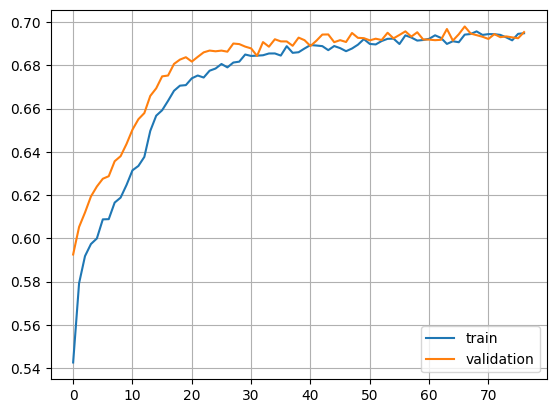

In [67]:
my_cnn1d_2 = CNN_1d(n_output_channels=1, filter_widths=[5,1], num_chunks=5, max_pool_factor=4, nchannels=[4,16,16], n_hidden=16, dropout=0.2)

my_cnn1d_2, train_accs, val_accs = train_model(my_cnn1d_2, train_data, validation_data)

plt.plot(train_accs, label="train")
plt.plot(val_accs, label="validation")
plt.legend()
plt.grid(which="both")

b. Describe the setting choices you have made to underfit the data and explain why these settings contributed to a low train and validation accuracy. [1 point]

**Explanation**

The setting choices I chose to underfit the data was to change the overall dimensions of the CNN, namely reducing the filter widths, the number of channels, and the number of hidden units in the fully connected layers (following the convolution layers). These setting changes contributed to a low train and validation accuracy (accuracy scores for both training and validation of approximately 0.60, a score only slightly better than 0.50 expected of random guessing) because the width of filters and the number of channels impact the resulting feature maps from the convolutional layers. Reducing the width of the filter impacts the resulting score by forcing the model to see shorter stretches of the sequence, missing possible patterns. The reduction of channel numbers decreases the complexity of the model by reducing the number of feature maps and subsequently the number of distinct patterns the model can detect. The reduction of the number of hidden units impacted the training and validation accuracy score by reducing the number of features the model can combine before its output. Thus, despite any information found from the convolution layers, it cannot reach the output. Additionally, n_hidden appeared to have the most impact on the resulting training and validation accuracy scores.

## Question 2 [4 points]

a. Find settings of `CNN_1d` that that overfit (high train accuracy but low validation accuracy). [3 points]

Receptive field: 30 Chunk size: 16 Number chunks: 5
Epoch 1 took 3.28s. Train loss: 0.6808 acc: 0.6202. Val loss: 0.5860 acc: 0.6906. Patience left: 10
Epoch 2 took 2.19s. Train loss: 0.5536 acc: 0.7157. Val loss: 0.6194 acc: 0.6572. Patience left: 9
Epoch 3 took 2.12s. Train loss: 0.5077 acc: 0.7511. Val loss: 0.9421 acc: 0.5642. Patience left: 8
Epoch 4 took 2.11s. Train loss: 0.4571 acc: 0.7838. Val loss: 0.9144 acc: 0.5934. Patience left: 7
Epoch 5 took 2.18s. Train loss: 0.3988 acc: 0.8212. Val loss: 0.7483 acc: 0.6887. Patience left: 6
Epoch 6 took 3.08s. Train loss: 0.3429 acc: 0.8509. Val loss: 1.6885 acc: 0.5666. Patience left: 5
Epoch 7 took 2.99s. Train loss: 0.3054 acc: 0.8685. Val loss: 1.4984 acc: 0.5877. Patience left: 4
Epoch 8 took 2.24s. Train loss: 0.2603 acc: 0.8896. Val loss: 0.8423 acc: 0.6833. Patience left: 3
Epoch 9 took 2.17s. Train loss: 0.2506 acc: 0.8962. Val loss: 2.4682 acc: 0.5195. Patience left: 2
Epoch 10 took 2.12s. Train loss: 0.2056 acc: 0.9149. Val

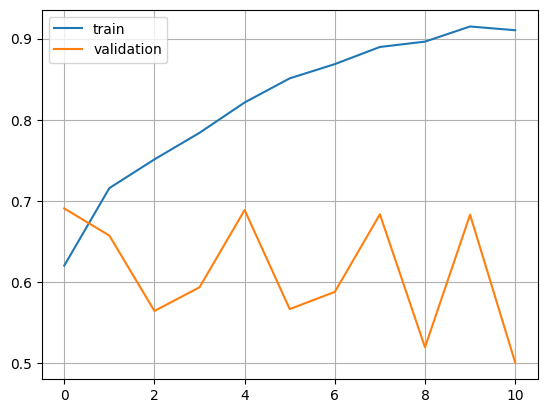

In [68]:
my_cnn1d_3 = CNN_1d(n_output_channels=1, filter_widths=[15,5], num_chunks=5, max_pool_factor=4, nchannels=[4,128,128], n_hidden=512, dropout=0)

my_cnn1d_3, train_accs, val_accs = train_model(my_cnn1d_3, train_data, validation_data)

plt.plot(train_accs, label="train")
plt.plot(val_accs, label="validation")
plt.legend()
plt.grid(which="both")

b. Describe the setting choices you have made to overfit the data and explain why these settings contributed to a high train and low validation accuracy. [1 point]

**Explanation:**
The above plot indicates clear overfitting, particularly the contrast between the training accuracy score and the resulting validation accuracy score. The training accuracy score across epochs increased, rising to 0.90. Yet, validation accuracy fluctuated between roughly 0.53 and 0.69 before falling to 0.50 at the final epoch. As such, training loss was around .20 while validation loss was around 3. This gap showcases overfitting, indicating that the model was possibly memorizing patterns from the training dataset rather than learning generalizable patterns for new sequences.

The setting changes done to contribute to overfitting are as follows: increasing channels, larger hidden layer, and removing dropout. I raised the number of channels in both convolutional layers from 32 to 128, making the model learn four times as many sequence filters per layer and more weights overall. Thus, the model may be able to pick up patterns that occur in training sequences rather than true possible binding patterns. More so, I increased the n_hidden to 512 from 32, enlarging the fully connected layer where the convolutional features are combined. This change made it so the model was able to memorize training patterns as opposed to learning generalizable patterns. Finally, I set dropout to 0, removing a parameter that prevents the model from fitting to noise. In doing this, the model is more likely to fit to noise found in the training data. As such, the overall gap between the training and validation scores underscores the possibility that the model learned and memorized the training data rather than general patterns about the sequences.

## Question 3  [6 points]

a. Carefully explore varying one architectural choice (e.g.  depth, number of channels, filter width, regularization, pooling factor, optimizer, learning rate, batch size, activation function, normalization, or skip connections). Report the final train and validation accuracy as a function of this choice.

For example you might vary the number of convolutional layers from 1 to 4, keeping everything else the same, and plot validation accuracy vs number of layers. [4 points]

Receptive field: 30 Chunk size: 16 Number chunks: 5
Epoch 1 took 3.07s. Train loss: 0.6766 acc: 0.5692. Val loss: 0.6525 acc: 0.6066. Patience left: 10
Epoch 2 took 2.44s. Train loss: 0.6586 acc: 0.5965. Val loss: 0.6419 acc: 0.6267. Patience left: 10
Epoch 3 took 1.67s. Train loss: 0.6515 acc: 0.6043. Val loss: 0.6342 acc: 0.6338. Patience left: 10
Epoch 4 took 1.65s. Train loss: 0.6448 acc: 0.6184. Val loss: 0.6258 acc: 0.6435. Patience left: 10
Epoch 5 took 1.63s. Train loss: 0.6375 acc: 0.6276. Val loss: 0.6152 acc: 0.6538. Patience left: 10
Epoch 6 took 1.66s. Train loss: 0.6314 acc: 0.6383. Val loss: 0.6070 acc: 0.6661. Patience left: 10
Epoch 7 took 1.71s. Train loss: 0.6256 acc: 0.6443. Val loss: 0.5983 acc: 0.6800. Patience left: 10
Epoch 8 took 2.41s. Train loss: 0.6176 acc: 0.6557. Val loss: 0.5904 acc: 0.6885. Patience left: 10
Epoch 9 took 2.87s. Train loss: 0.6148 acc: 0.6611. Val loss: 0.5866 acc: 0.6878. Patience left: 10
Epoch 10 took 1.67s. Train loss: 0.6060 acc: 0.6

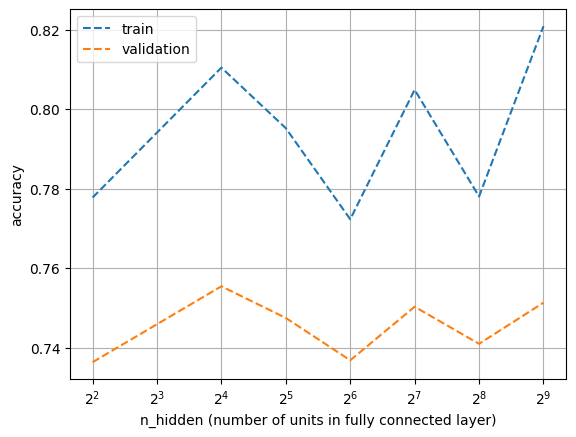

In [69]:
n_hidden_values = [4, 16, 32, 64, 128, 256, 512]
final_train_accs = []
final_val_accs = []

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for n_hidden in n_hidden_values:
    torch.manual_seed(42)
    model = CNN_1d(n_output_channels=1, filter_widths=[15,5], num_chunks=5,
                   max_pool_factor=4, nchannels=[4,32,32], n_hidden=n_hidden, dropout=0.2)

    model, train_accs, val_accs = train_model(model, train_data, validation_data, verbose=False)

    # evaluating the best model
    train_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(train_data, genome, model.seq_len), batch_size=1000)
    val_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(validation_data, genome, model.seq_len), batch_size=1000)
    optimizer = torch.optim.Adam(model.parameters())
    _, train_acc = run_one_epoch(False, train_loader, model, optimizer, device)
    _, val_acc = run_one_epoch(False, val_loader, model, optimizer, device)

    final_train_accs.append(train_acc)
    final_val_accs.append(val_acc)
    print("n_hidden=%i  train acc: %.4f  val acc: %.4f" % (n_hidden, train_acc, val_acc))

plt.plot(n_hidden_values, final_train_accs, "--", label="train")
plt.plot(n_hidden_values, final_val_accs, "--", label="validation")
plt.xscale("log", base=2)
plt.xlabel("n_hidden (number of units in fully connected layer)")
plt.ylabel("accuracy")
plt.legend()
plt.grid(which="both")

b. For your selected architectural choice, discuss how and why varying this option affected your training and validation accuracy. [2 points]

**Explanation:**

I changed the number of units in the fully connected layer (n_hidden) from values 4 to 512, keeping all other settings constant and at their default values. Validation accuracy remained nearly consistent, ranging between 0.74 and 0.75, while training accuracy ranged from 0.78 to 0.81. The gap between the two scores stayed at around 0.05 and 0.06 throughout the values of n_hidden, and thus the larger n_hidden values did not seem to impact overfitting of the model. The flucuations in the chart move together within both scores, suggesting they may be random variation as opposed to being an effect of the changing n_hidden vlaues. Thus, these results suggest that, with dropout and early stopping, model performance in training or validation is not as impacted by the size of the hidden layer as opposed to other hyperparameters such as the number of convolutional layers.

## Question 4 [8 points]

a. Get as good validation accuracy as you can! Vary at least one thing that you didn't explore in Question 3, and show (with plots) or describe how you got to your final model. [4 points]

Optionally you can try some more advanced extensions, e.g.
1. Adding some [Recurrent Layers](https://pytorch.org/docs/stable/nn.html#recurrent-layers). Be warned that `torch` assumes the opposite dimensions for convolutional vs recurrent layers so you'll want to use `torch.transpose` appropriately.
2. Transcription factors can bind to either strand of the DNA so you might want to include the [reverse complement](https://www.bx.psu.edu/old/courses/bx-fall08/definitions.html) (RC) in addition to the normal input. The simplest way to do this would be to train on both the original sequence and the RC (a form of data augmentation). Slightly fancier: run a copy of the network on the RC and take the max of the output from the two networks. Fancier approach here: https://www.biorxiv.org/content/10.1101/103663v1
3. Changing `BedPeaksDataset` to generate more negative examples in the space between peaks (although you'd only want to do this on the training data so you keep a fixed validation set). You will want to "cancel out" the additional negative examples by downweighting them in the loss.

Receptive field: 30 Chunk size: 16 Number chunks: 5
Epoch 1 took 1.57s. Train loss: 0.6779 acc: 0.5673. Val loss: 0.6596 acc: 0.5950. Patience left: 10
Epoch 2 took 1.57s. Train loss: 0.6616 acc: 0.5985. Val loss: 0.6483 acc: 0.6148. Patience left: 10
Epoch 3 took 1.56s. Train loss: 0.6547 acc: 0.6074. Val loss: 0.6428 acc: 0.6207. Patience left: 10
Epoch 4 took 1.53s. Train loss: 0.6484 acc: 0.6152. Val loss: 0.6351 acc: 0.6292. Patience left: 10
Epoch 5 took 2.07s. Train loss: 0.6428 acc: 0.6243. Val loss: 0.6278 acc: 0.6389. Patience left: 10
Epoch 6 took 3.14s. Train loss: 0.6379 acc: 0.6311. Val loss: 0.6230 acc: 0.6435. Patience left: 10
Epoch 7 took 1.68s. Train loss: 0.6316 acc: 0.6363. Val loss: 0.6102 acc: 0.6597. Patience left: 10
Epoch 8 took 1.54s. Train loss: 0.6253 acc: 0.6449. Val loss: 0.6007 acc: 0.6712. Patience left: 10
Epoch 9 took 1.57s. Train loss: 0.6185 acc: 0.6541. Val loss: 0.5933 acc: 0.6838. Patience left: 10
Epoch 10 took 1.55s. Train loss: 0.6108 acc: 0.6

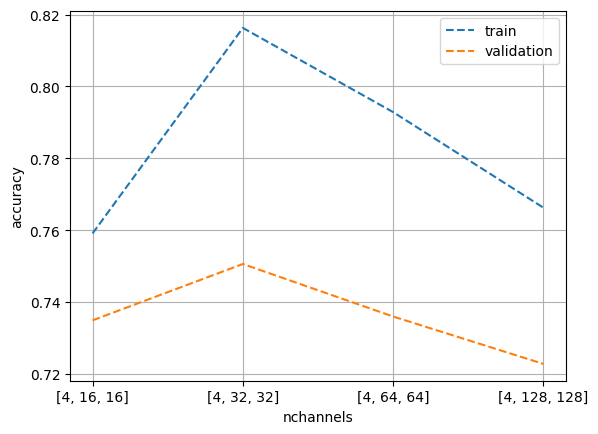

In [70]:
# Changing the number of channels:

import torch
import timeit

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

channel_variations = [[4,16,16], [4,32,32], [4,64,64], [4,128,128]]
sweep_train_accs = []
sweep_val_accs = []

for nchannels in channel_variations:
    torch.manual_seed(42)
    model = CNN_1d(n_output_channels=1, filter_widths=[15,5], num_chunks=5,
                   max_pool_factor=4, nchannels=nchannels, n_hidden=32, dropout=0.2)
    model, _, _ = train_model(model, train_data, validation_data, verbose=False)


    train_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(train_data, genome, model.seq_len), batch_size=1000)
    val_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(validation_data, genome, model.seq_len), batch_size=1000)
    optimizer = torch.optim.Adam(model.parameters())
    _, train_acc = run_one_epoch(False, train_loader, model, optimizer, device)
    _, val_acc = run_one_epoch(False, val_loader, model, optimizer, device)

    sweep_train_accs.append(train_acc)
    sweep_val_accs.append(val_acc)
    print(nchannels, "train: %.4f  val: %.4f" % (train_acc, val_acc))

xs = range(len(channel_variations))
plt.plot(xs, sweep_train_accs, "--", label="train")
plt.plot(xs, sweep_val_accs, "--", label="validation")
plt.xticks(xs, [str(c) for c in channel_variations])
plt.xlabel("nchannels"); plt.ylabel("accuracy")
plt.legend(); plt.grid(which="both")

Receptive field: 24 Chunk size: 16 Number chunks: 5


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


Epoch 1 took 1.62s. Train loss: 0.6771 acc: 0.5688. Val loss: 0.6508 acc: 0.6154. Patience left: 10
Epoch 2 took 1.59s. Train loss: 0.6552 acc: 0.6057. Val loss: 0.6382 acc: 0.6316. Patience left: 10
Epoch 3 took 1.56s. Train loss: 0.6462 acc: 0.6166. Val loss: 0.6301 acc: 0.6376. Patience left: 10
Epoch 4 took 1.54s. Train loss: 0.6400 acc: 0.6247. Val loss: 0.6238 acc: 0.6442. Patience left: 10
Epoch 5 took 1.56s. Train loss: 0.6329 acc: 0.6367. Val loss: 0.6141 acc: 0.6576. Patience left: 10
Epoch 6 took 2.34s. Train loss: 0.6282 acc: 0.6397. Val loss: 0.6106 acc: 0.6622. Patience left: 10
Epoch 7 took 2.65s. Train loss: 0.6190 acc: 0.6511. Val loss: 0.5986 acc: 0.6794. Patience left: 10
Epoch 8 took 1.60s. Train loss: 0.6131 acc: 0.6599. Val loss: 0.5906 acc: 0.6864. Patience left: 10
Epoch 9 took 1.56s. Train loss: 0.6059 acc: 0.6674. Val loss: 0.5814 acc: 0.6924. Patience left: 10
Epoch 10 took 1.58s. Train loss: 0.5998 acc: 0.6718. Val loss: 0.5771 acc: 0.6955. Patience left: 10

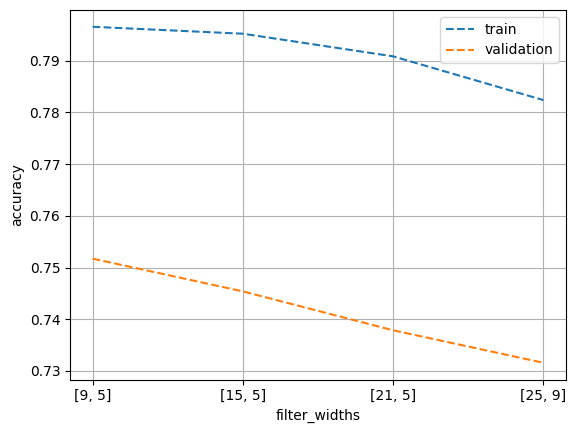

In [38]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import timeit


width_options = [[9,5], [15,5], [21,5], [25,9]]
sweep_train_accs = []
sweep_val_accs = []

for filter_widths in width_options:
    torch.manual_seed(42)
    model = CNN_1d(n_output_channels=1, filter_widths=filter_widths, num_chunks=5,
                   max_pool_factor=4, nchannels=[4,32,32], n_hidden=32, dropout=0.2)
    model, _, _ = train_model(model, train_data, validation_data, verbose=False)


    train_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(train_data, genome, model.seq_len), batch_size=1000)
    val_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(validation_data, genome, model.seq_len), batch_size=1000)
    optimizer = torch.optim.Adam(model.parameters())
    _, train_acc = run_one_epoch(False, train_loader, model, optimizer, device)
    _, val_acc = run_one_epoch(False, val_loader, model, optimizer, device)

    sweep_train_accs.append(train_acc)
    sweep_val_accs.append(val_acc)
    print(filter_widths, "train: %.4f  val: %.4f" % (train_acc, val_acc))

xs = range(len(width_options))
plt.plot(xs, sweep_train_accs, "--", label="train")
plt.plot(xs, sweep_val_accs, "--", label="validation")
plt.xticks(xs, [str(c) for c in width_options])
plt.xlabel("filter_widths"); plt.ylabel("accuracy")
plt.legend(); plt.grid(which="both")

Receptive field: 30 Chunk size: 16 Number chunks: 5


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


Epoch 1 took 2.04s. Train loss: 0.6382 acc: 0.6249. Val loss: 0.6310 acc: 0.6486. Patience left: 10
Epoch 2 took 1.65s. Train loss: 0.5735 acc: 0.7005. Val loss: 0.5763 acc: 0.6991. Patience left: 10
Epoch 3 took 1.61s. Train loss: 0.5477 acc: 0.7229. Val loss: 0.5780 acc: 0.6975. Patience left: 9
Epoch 4 took 1.63s. Train loss: 0.5310 acc: 0.7363. Val loss: 0.6016 acc: 0.6870. Patience left: 8
Epoch 5 took 2.02s. Train loss: 0.5178 acc: 0.7446. Val loss: 0.6150 acc: 0.6813. Patience left: 7
Epoch 6 took 2.89s. Train loss: 0.5062 acc: 0.7527. Val loss: 0.6150 acc: 0.6857. Patience left: 6
Epoch 7 took 1.79s. Train loss: 0.4963 acc: 0.7593. Val loss: 0.6195 acc: 0.6850. Patience left: 5
Epoch 8 took 1.64s. Train loss: 0.4880 acc: 0.7648. Val loss: 0.6226 acc: 0.6860. Patience left: 4
Epoch 9 took 1.64s. Train loss: 0.4804 acc: 0.7689. Val loss: 0.6349 acc: 0.6800. Patience left: 3
Epoch 10 took 1.69s. Train loss: 0.4738 acc: 0.7729. Val loss: 0.6553 acc: 0.6746. Patience left: 2
Epoch 1

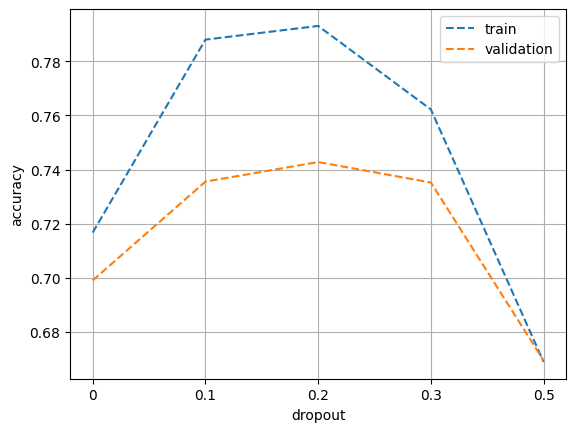

In [40]:
dropout_options = [0, 0.1, 0.2, 0.3, 0.5]
sweep_train_accs = []
sweep_val_accs = []

for dropout in dropout_options:
    torch.manual_seed(42)
    model = CNN_1d(n_output_channels=1, filter_widths=[9,5], num_chunks=5,
                   max_pool_factor=4, nchannels=[4,32,32], n_hidden=32, dropout=dropout)
    model, _, _ = train_model(model, train_data, validation_data, verbose=False)


    train_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(train_data, genome, model.seq_len), batch_size=1000)
    val_loader = torch.utils.data.DataLoader(
        BedPeaksDataset(validation_data, genome, model.seq_len), batch_size=1000)
    optimizer = torch.optim.Adam(model.parameters())
    _, train_acc = run_one_epoch(False, train_loader, model, optimizer, device)
    _, val_acc = run_one_epoch(False, val_loader, model, optimizer, device)

    sweep_train_accs.append(train_acc)
    sweep_val_accs.append(val_acc)
    print(dropout, "train: %.4f  val: %.4f" % (train_acc, val_acc))

xs = range(len(dropout_options))
plt.plot(xs, sweep_train_accs, "--", label="train")
plt.plot(xs, sweep_val_accs, "--", label="validation")
plt.xticks(xs, [str(c) for c in dropout_options])
plt.xlabel("dropout"); plt.ylabel("accuracy")
plt.legend(); plt.grid(which="both")

Receptive field: 24 Chunk size: 16 Number chunks: 5


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


Epoch 1 took 2.17s. Train loss: 0.6678 acc: 0.5839. Val loss: 0.6470 acc: 0.6077. Patience left: 10
Epoch 2 took 2.81s. Train loss: 0.6485 acc: 0.6160. Val loss: 0.6398 acc: 0.6194. Patience left: 10
Epoch 3 took 2.49s. Train loss: 0.6386 acc: 0.6273. Val loss: 0.6297 acc: 0.6358. Patience left: 10
Epoch 4 took 1.83s. Train loss: 0.6283 acc: 0.6409. Val loss: 0.6220 acc: 0.6472. Patience left: 10
Epoch 5 took 1.81s. Train loss: 0.6189 acc: 0.6520. Val loss: 0.6110 acc: 0.6581. Patience left: 10
Epoch 6 took 1.84s. Train loss: 0.6123 acc: 0.6600. Val loss: 0.6112 acc: 0.6625. Patience left: 9
Epoch 7 took 3.05s. Train loss: 0.6054 acc: 0.6699. Val loss: 0.6065 acc: 0.6719. Patience left: 10
Epoch 8 took 2.59s. Train loss: 0.5995 acc: 0.6725. Val loss: 0.5828 acc: 0.6915. Patience left: 10
Epoch 9 took 4.29s. Train loss: 0.5901 acc: 0.6840. Val loss: 0.5813 acc: 0.6918. Patience left: 10
Epoch 10 took 2.26s. Train loss: 0.5827 acc: 0.6904. Val loss: 0.5685 acc: 0.7041. Patience left: 10


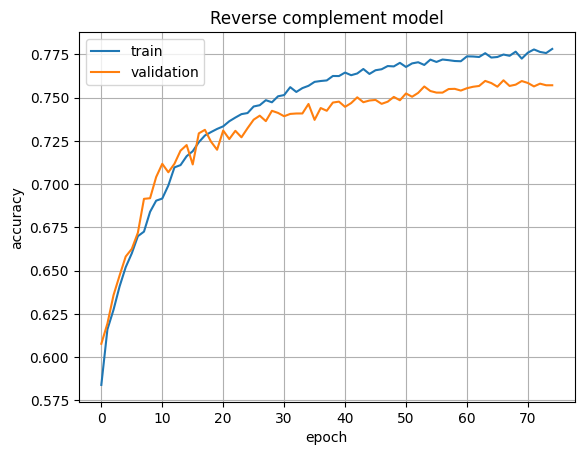

In [43]:
# Reverse complement with the best settings from before
class RCModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.seq_len = model.seq_len

    def forward(self, x):
        return torch.max(self.model(x), self.model(x.flip(dims=[1, 2])))

torch.manual_seed(42)
base = CNN_1d(n_output_channels=1, filter_widths=[9,5], num_chunks=5, max_pool_factor=4,
              nchannels=[4,32,32], n_hidden=32, dropout=0.2)
rc_model, rc_train_accs, rc_val_accs = train_model(RCModel(base), train_data, validation_data, verbose=False)

train_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(train_data, genome, rc_model.seq_len), batch_size=1000)
val_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(validation_data, genome, rc_model.seq_len), batch_size=1000)
optimizer = torch.optim.Adam(rc_model.parameters())
_, train_acc = run_one_epoch(False, train_loader, rc_model, optimizer, device)
_, val_acc = run_one_epoch(False, val_loader, rc_model, optimizer, device)
print("Reverse Complement model:  train: %.4f  val: %.4f" % (train_acc, val_acc))

plt.plot(rc_train_accs, label="train")
plt.plot(rc_val_accs, label="validation")
plt.xlabel("epoch"); plt.ylabel("accuracy")
plt.title("Reverse complement model")
plt.legend(); plt.grid(which="both")
plt.show()

In [55]:
# Reverse complement with different seeds to double check
class RCModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.seq_len = model.seq_len

    def forward(self, x):
        return torch.max(self.model(x), self.model(x.flip(dims=[1, 2])))

torch.manual_seed(1)
base = CNN_1d(n_output_channels=1, filter_widths=[9,5], num_chunks=5, max_pool_factor=4,
              nchannels=[4,32,32], n_hidden=32, dropout=0.2)
rc_model, _, _ = train_model(RCModel(base), train_data, validation_data, verbose=False)

train_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(train_data, genome, rc_model.seq_len), batch_size=1000)
val_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(validation_data, genome, rc_model.seq_len), batch_size=1000)
optimizer = torch.optim.Adam(rc_model.parameters())
_, train_acc = run_one_epoch(False, train_loader, rc_model, optimizer, device)
_, val_acc = run_one_epoch(False, val_loader, rc_model, optimizer, device)
print("Reverse Complement model:  train: %.4f  val: %.4f" % (train_acc, val_acc))

Receptive field: 24 Chunk size: 16 Number chunks: 5


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


Reverse Complement model:  train: 0.8037  val: 0.7609


In [45]:
class RCModel(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.seq_len = model.seq_len

    def forward(self, x):
        return torch.max(self.model(x), self.model(x.flip(dims=[1, 2])))

torch.manual_seed(2)
base = CNN_1d(n_output_channels=1, filter_widths=[9,5], num_chunks=5, max_pool_factor=4,
              nchannels=[4,32,32], n_hidden=32, dropout=0.2)
rc_model, _, _ = train_model(RCModel(base), train_data, validation_data, verbose=False)

train_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(train_data, genome, rc_model.seq_len), batch_size=1000)
val_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(validation_data, genome, rc_model.seq_len), batch_size=1000)
optimizer = torch.optim.Adam(rc_model.parameters())
_, train_acc = run_one_epoch(False, train_loader, rc_model, optimizer, device)
_, val_acc = run_one_epoch(False, val_loader, rc_model, optimizer, device)
print("Reverse Complement model:  train: %.4f  val: %.4f" % (train_acc, val_acc))

Receptive field: 24 Chunk size: 16 Number chunks: 5
Epoch 1 took 2.24s. Train loss: 0.6684 acc: 0.5811. Val loss: 0.6462 acc: 0.6110. Patience left: 10
Epoch 2 took 1.90s. Train loss: 0.6488 acc: 0.6141. Val loss: 0.6461 acc: 0.6135. Patience left: 10
Epoch 3 took 3.03s. Train loss: 0.6379 acc: 0.6303. Val loss: 0.6373 acc: 0.6330. Patience left: 10
Epoch 4 took 3.11s. Train loss: 0.6303 acc: 0.6374. Val loss: 0.6410 acc: 0.6291. Patience left: 9
Epoch 5 took 2.31s. Train loss: 0.6194 acc: 0.6487. Val loss: 0.6374 acc: 0.6349. Patience left: 8
Epoch 6 took 1.98s. Train loss: 0.6110 acc: 0.6630. Val loss: 0.6462 acc: 0.6281. Patience left: 7
Epoch 7 took 1.90s. Train loss: 0.6019 acc: 0.6729. Val loss: 0.6409 acc: 0.6349. Patience left: 6
Epoch 8 took 2.20s. Train loss: 0.5935 acc: 0.6796. Val loss: 0.6224 acc: 0.6533. Patience left: 10
Epoch 9 took 2.04s. Train loss: 0.5895 acc: 0.6856. Val loss: 0.6414 acc: 0.6369. Patience left: 9
Epoch 10 took 3.08s. Train loss: 0.5836 acc: 0.6917. 

b. What gave you the biggest boost in performance? Why do you think that is? [2 points]

**Explanation:**

No singlular change produced a large improvement, however the default hyperparameters were the closest to the most optimal settings. Moreover, the reverse complement model gave the highest validation accuracy, with three respective accuracies of 0.758 (seed=42), 0.761 (seed=1), and 0.745 (seed=2), compared to 0.752 for the same settings without the reverse complement. However, the difference in performance between the different seeds is larger than the improvement for the reverse complement model, suggesting that the improvement may not entirely be due to the reverse complement change. In terms of hyperparameter tuning, the reduction of the filter widths from [15,5] to [9,5] gave a small increase in validation accuracy from 0.745 to 0.752. The dropout allowed the model to avoid bad values with validation accuracy dropping to .70 without drop out and 0.67 with a dropout of 0.5.

I believe reverse complement helped the model because transcription factors bind to double-stranded DNA, so transcription motifs can appear on either strand. A CNN without reverse compelment would have to learn each factor separately in both orientations and thus split its resulting filters and training data between those orientations. Running the model on both strands and taking the max would allow the filter to recognize a motif in either orientation.

Yet, I believe gains were small because chromatin accessibility is harder to predict from sequences as opposed to CTCF binding. Sequence data includes a variety of transcription factors and cell-type specific context, limiting how well a sequence-only model can do.

c.  Use some model interpretability technique to visualize why the model has made the assignments it did for a few examples. This can be one of the methods shown above (in silico mutagenesis or saliency maps) or one of the methods linked under *Other interpretation approaches*. [2 points]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.2/13.2 MB 41.7 MB/s  0:00:00


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/dropout.py:176: UserWarning: dropout2d: Received a 3D input to dropout2d and assuming that channel-wise 1D dropout behavior is desired - input is interpreted as shape (N, C, L), where C is the channel dim. This behavior will change in a future release to interpret the input as one without a batch dimension, i.e. shape (C, H, W). To maintain the 1D channel-wise dropout behavior, please switch to using dropout1d instead.
  return F.dropout2d(input, self.p, self.training, self.inplace)


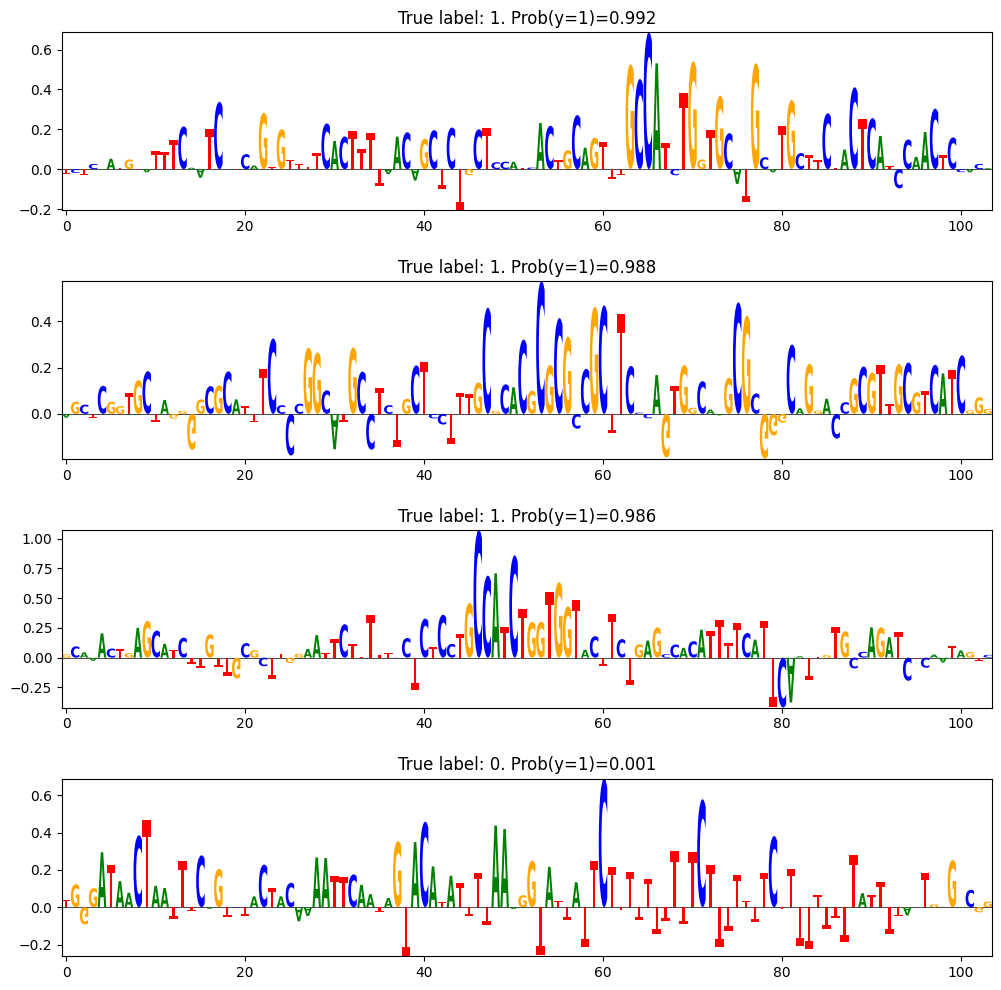

In [50]:
!pip install logomaker
import logomaker
rc_model.eval()
torch.set_grad_enabled(True)


val_loader = torch.utils.data.DataLoader(
    BedPeaksDataset(validation_data, genome, rc_model.seq_len), batch_size=1000)
x_cpu, y_cpu = next(iter(val_loader))
x = x_cpu.to(device).requires_grad_()


logits = rc_model(x).squeeze()
logits.backward(torch.ones_like(logits))
saliency = (x.grad * x).detach().cpu().numpy()
probs = torch.sigmoid(logits).detach().cpu().numpy()
y_np = y_cpu.numpy()

# picking 3 positives
pos = np.where(y_np == 1)[0]
neg = np.where(y_np == 0)[0]
top_pos = pos[np.argsort(probs[pos])[::-1][:3]]
top_neg = neg[np.argsort(probs[neg])[:1]]
examples = list(top_pos) + list(top_neg)

plt.figure(figsize=(12, 12))
for k, i in enumerate(examples):
    ax = plt.subplot(len(examples), 1, k + 1)
    df = pd.DataFrame(saliency[i].T, columns=["A", "C", "G", "T"])
    logomaker.Logo(df, ax=ax)
    ax.set_title("True label: %i. Prob(y=1)=%.3f" % (y_np[i], probs[i]))
plt.subplots_adjust(hspace=0.4)

## Question 5  [6 points]

The final task is to submit your best performing model's predictions on chromosomes 1 and 2 to [our Kaggle competition](https://www.kaggle.com/competitions/ml4fg-predict-atac-from-sequence-f26). Please find the invite link to join the competition on the Courseworks assignment page.

You can change what train/validation split you use here also if you want: e.g. you could do K-fold cross-validation or even retrain including the validation data if you think it will help (although early stopping may not work any more).

First we'll need to load the test regions:

In [53]:
test_data = pd.read_csv(DATADIR + "ATAC_test_regions.bed.gz", sep='\t', names=("chrom","start","end"))
test_data.head(10)

,chrom,start,end
0,chr1,713980,714180
1,chr1,2159194,2159394
2,chr1,1185163,1185363
3,chr1,2721699,2721899
4,chr1,2232837,2233037
5,chr1,2462557,2462757
6,chr1,2601580,2601780
7,chr1,2638010,2638210
8,chr1,3393795,3393995
9,chr1,3418525,3418725


Unlike the training data we've included random (in number and in genomic position) negative (no binding) regions in this bed file since otherwise you'd know implicitly that all the loaded regions are positives!

We'll use a new `Dataset` class and `DataLoader` to match predictions on the test data in batches:

In [56]:
class BedPeaksDatasetTest(torch.utils.data.IterableDataset):

    def __init__(self, atac_data, genome, context_length):
        super(BedPeaksDatasetTest, self).__init__()
        self.context_length = context_length
        self.atac_data = atac_data
        self.genome = genome

    def __iter__(self):
        for row in self.atac_data.itertuples():
            midpoint = int(.5 * (row.start + row.end))
            seq = self.genome[row.chrom][ midpoint - self.context_length//2:midpoint + self.context_length//2]
            yield(one_hot(seq))

test_dataset = BedPeaksDatasetTest(test_data, genome, rc_model.seq_len)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=1000, num_workers=0)

rc_model.eval()
outputs = []
with torch.no_grad():
    for x in test_dataloader:
        x = x.to(device)
        output = torch.sigmoid(rc_model(x).squeeze())
        outputs.append(output.cpu().numpy())
output_np = np.concatenate(outputs)

my_solution = pd.DataFrame(data={"Id": range(len(output_np)), "Predicted": output_np})
my_solution.to_csv("my_submission.csv", index=False)
print(len(my_solution), len(test_data))  # these should match
my_solution.head()

18156 18156


,Id,Predicted
0,0,0.608228
1,1,0.960191
2,2,0.717955
3,3,0.512424
4,4,0.110714


Before making a submission, make sure to join the Kaggle competition using the announced invite link or on the Courseworks assignment page.

There are two ways to make a submission:

**Option 1: Submit via the website**

1. Sign into Kaggle via your Columbia Google account (if you have one).
2. Make sure your team name is your actual name so we know which is your submission.
3. Download `my_submission.csv` using the `Files` browser on the left
4. Upload your submission and see where you get on the leaderboard!

**Option 2: Submit via the command line interface (CLI) on Colab**

Follow the cells below to install the `kaggle` CLI and authenticate. Please login using you Columbia Google account (if you have one).

In [ ]:
# Install Kaggle CLI
!pip install kaggle --upgrade

In [ ]:
# Log into Kaggle (this will ask you to open a link, sign in, then paste a code here)
!kaggle auth login

In [ ]:
# Submit
!kaggle competitions submit -c ml4fg-predict-atac-from-sequence-f26 -f my_submission.csv -m "Message"

Submission is worth 2 points, beating our baseline gets you 2 points and the other 2 points are for your tertile in the class (e.g. you get 2 points if you're in the top third, 1 point if you're in the middle third).

Our baseline has been submitted under the name "Baseline" with an AUROC score of 0.81009.

Get leaderboard to check your performance (or view it online on Kaggle)

In [ ]:
!kaggle competitions leaderboard ml4fg-predict-atac-from-sequence-f26 --show